In [72]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import joblib

In [73]:
df = pd.read_csv("dataset.csv")

In [74]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [75]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,18.000000,9.000000,17.000000,1.000000,17.000000,21.000000,29.000000,34.000000,32.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                             4424

In [77]:
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrollment                                 0
International                                     0
Curricular u

In [78]:
print("Duplicate Rows :", df.duplicated().sum())

df.drop_duplicates(inplace=True)

Duplicate Rows : 0


In [79]:
print(df["Target"].value_counts())

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


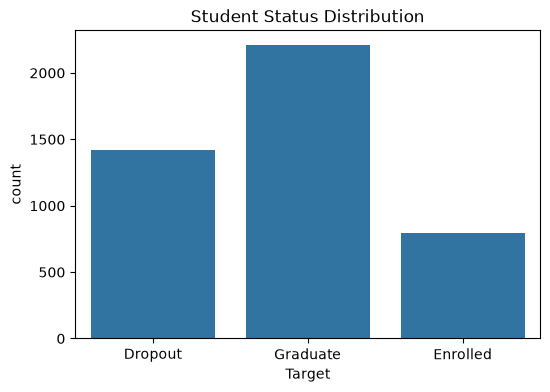

In [80]:
plt.figure(figsize=(6,4))
sns.countplot(x="Target", data=df)
plt.title("Student Status Distribution")
plt.show()

In [81]:
df.dtypes

Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender                                              int64
Scholarship holder                                  int64
Age at enrollm

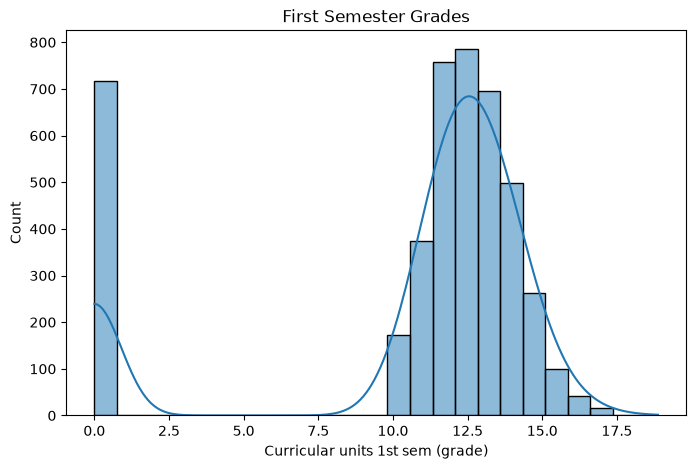

In [82]:
plt.figure(figsize=(8,5))

sns.histplot(df["Curricular units 1st sem (grade)"],
             bins=25,
             kde=True)

plt.title("First Semester Grades")

plt.show()

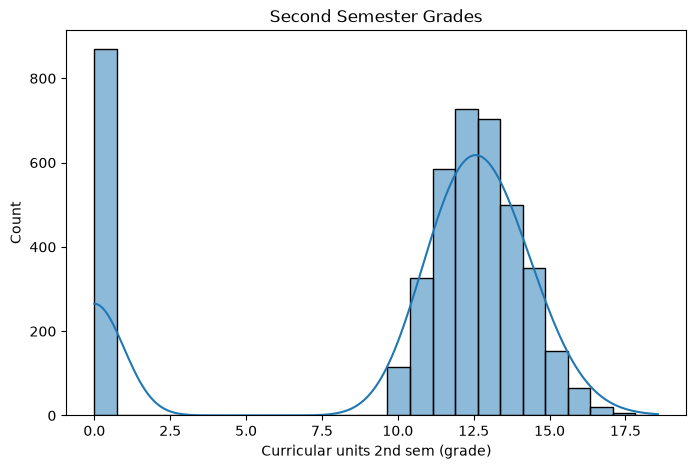

In [83]:
plt.figure(figsize=(8,5))
sns.histplot(df["Curricular units 2nd sem (grade)"],
             bins=25,
             kde=True)
plt.title("Second Semester Grades")

plt.show()

In [84]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df["Target"] = label_encoder.fit_transform(df["Target"])
print(label_encoder.classes_)
mapping = dict(zip(label_encoder.classes_,
                   label_encoder.transform(label_encoder.classes_)))

print(mapping)

['Dropout' 'Enrolled' 'Graduate']
{'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}


In [85]:
# Feature Engineering

df["Total_Approved"] = (
    df["Curricular units 1st sem (approved)"] +
    df["Curricular units 2nd sem (approved)"]
)

df["Total_Enrolled"] = (
    df["Curricular units 1st sem (enrolled)"] +
    df["Curricular units 2nd sem (enrolled)"]
)

df["Total_Evaluations"] = (
    df["Curricular units 1st sem (evaluations)"] +
    df["Curricular units 2nd sem (evaluations)"]
)

df["Total_Credits"] = (
    df["Curricular units 1st sem (credited)"] +
    df["Curricular units 2nd sem (credited)"]
)

df["Average_Grade"] = (
    df["Curricular units 1st sem (grade)"] +
    df["Curricular units 2nd sem (grade)"]
) / 2

df["Approval_Rate"] = (
    df["Total_Approved"] /
    (df["Total_Enrolled"] + 1)
)

df["Evaluation_Efficiency"] = (
    df["Total_Approved"] /
    (df["Total_Evaluations"] + 1)
)

In [86]:
features = [
    "Age at enrollment",
    "Curricular units 2nd sem (credited)",
    "Previous qualification",
    "Debtor",
    "Tuition fees up to date",
    "Scholarship holder",
    "Gender"
]

X = df[features]
y = df["Target"]

In [87]:
X.head() 

,Age at enrollment,Curricular units 2nd sem (credited),Previous qualification,Debtor,Tuition fees up to date,Scholarship holder,Gender
0,20,0,1,0,1,0,1
1,19,0,1,0,0,0,1
2,19,0,1,0,0,0,1
3,20,0,1,0,1,0,0
4,45,0,1,0,1,0,0


In [88]:
y.head()

0    0
1    2
2    0
3    2
4    2
Name: Target, dtype: int64

In [89]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(3539, 7)
(885, 7)


### FEATURE SCALING

In [90]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### DECISION TREE

In [91]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(

    random_state=42

)
dt.fit(X_train,y_train)

y_pred_dt = dt.predict(X_test)

dt_accuracy = accuracy_score(

    y_test,

    y_pred_dt

)

print(dt_accuracy)

0.5672316384180791


In [92]:
print(classification_report(
    y_test,
    y_pred_dt
))

              precision    recall  f1-score   support

           0       0.55      0.57      0.56       284
           1       0.19      0.09      0.12       159
           2       0.63      0.74      0.68       442

    accuracy                           0.57       885
   macro avg       0.46      0.47      0.45       885
weighted avg       0.53      0.57      0.54       885



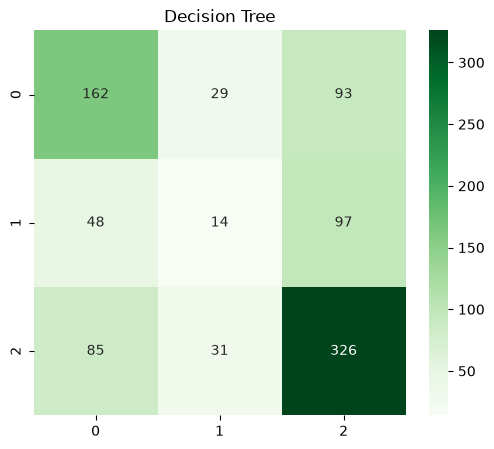

In [93]:
# CONFUSION MATRIX
cm = confusion_matrix(y_test,y_pred_dt)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Greens")

plt.title("Decision Tree")

plt.show()

### RANDOM FOREST

In [94]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200,random_state=42)
rf.fit(X_train,y_train)

y_pred_rf = rf.predict(X_test)

rf_accuracy = accuracy_score(y_test,y_pred_rf)

print(rf_accuracy)

0.5807909604519774


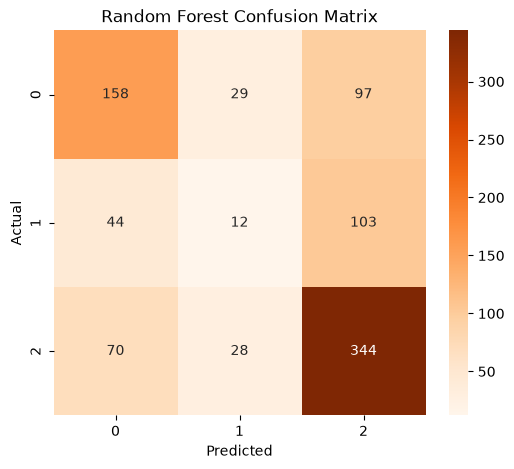

In [95]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [96]:
comparison = pd.DataFrame({"Model":["Decision Tree","Random Forest"],"Accuracy":[
        dt_accuracy,
        rf_accuracy, 
    ]
})

comparison.sort_values(by="Accuracy",ascending=False)

,Model,Accuracy
1,Random Forest,0.580791
0,Decision Tree,0.567232


### FEATURE IMPORTANCE

In [97]:
importance = pd.DataFrame({"Feature":X.columns,"Importance":rf.feature_importances_})

importance = importance.sort_values(by="Importance",ascending=False)

importance.head(15)

,Feature,Importance
0,Age at enrollment,0.385021
4,Tuition fees up to date,0.195162
1,Curricular units 2nd sem (credited),0.116503
5,Scholarship holder,0.102235
2,Previous qualification,0.089397
6,Gender,0.058418
3,Debtor,0.053263


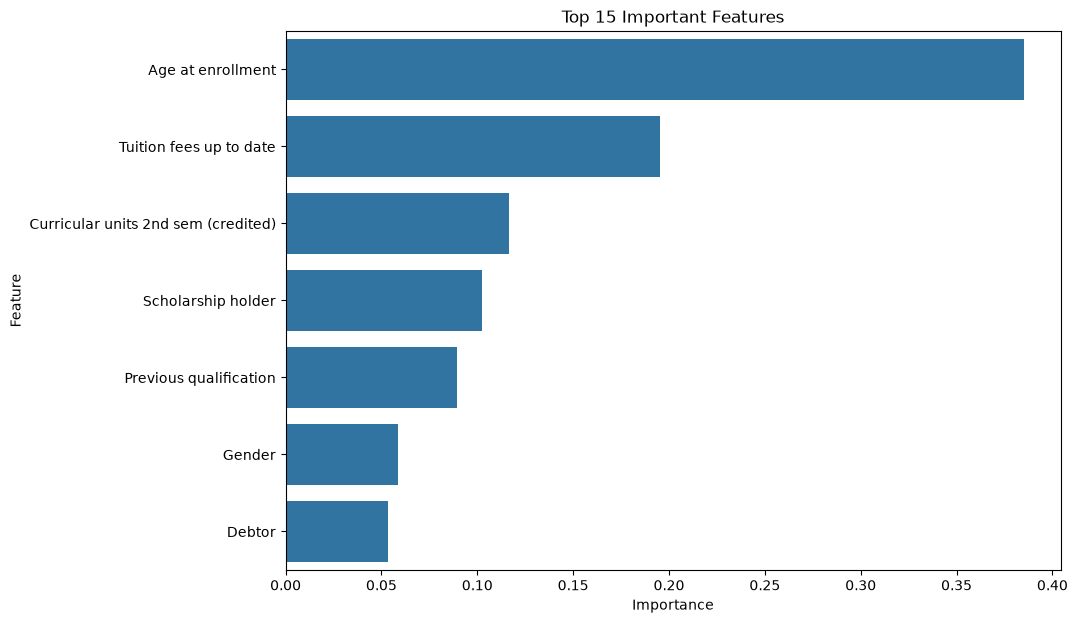

In [98]:
plt.figure(figsize=(10,7))
sns.barplot(data=importance.head(15),x="Importance",y="Feature")

plt.title("Top 15 Important Features")

plt.show()

In [99]:
joblib.dump(rf,"student_dropout_model.pkl")

joblib.dump(scaler,"scaler.pkl")

joblib.dump(label_encoder,"label_encoder.pkl")

['label_encoder.pkl']